# Partycjonowanie

Milestone 2 — zapis danych i porównanie wydajności.

- A: jeden plik Parquet.
- B: dane podzielone według stacji.
- C, opcjonalnie: te same partycje, inny sposób wyszukiwania plików.

W obu zapisach zachowujemy wszystkie kolumny i stosujemy Snappy.
Uruchom komórki po kolei lub wybierz **Run All**.

## 1. Ustawienia

`COMPARE_GLOB=True` dodaje wariant C. Próg niewielkiej różnicy ustawiamy w procentach.

In [6]:
from pathlib import Path
from uuid import uuid4
import inspect
import math
import runpy
import statistics
import polars as pl
from IPython.display import display, Markdown, Image

PROJECT_ROOT = None  # np. r"D:\Projekty\gios-bigdata"
AUTO_BUILD_FEATURES = True
REPEATS = 20
WARMUPS = 3
THREADS = None
ROW_GROUP_SIZE = 122880
WRITE_STATISTICS = False
READER_MODE = "all_files_list"
COMPARE_GLOB = False
PUBLISH_DATASET = True
SMALL_DIFFERENCE_PERCENT = 5.0


def find_root(start):
    start = Path(start).resolve()
    for candidate in (start, *start.parents):
        if (candidate / "scripts/partition_benchmark.py").is_file():
            return candidate
    raise FileNotFoundError("Ustaw PROJECT_ROOT na katalog projektu zawierający scripts/")


ROOT = find_root(PROJECT_ROOT if PROJECT_ROOT is not None else Path.cwd())
SILVER = ROOT / "data/silver"
SOURCE = SILVER / "pm25_pogoda_2024.parquet"
old = globals().pop("ctx", None)
if isinstance(old, dict) and old.get("con") is not None:
    old["con"].close()
del old
print("Projekt:", ROOT)
print("Dane:", SOURCE)

Projekt: D:\Projekty\gios-bigdata
Dane: D:\Projekty\gios-bigdata\data\silver\pm25_pogoda_2024.parquet


## 2. Dane wejściowe

Jeśli tabela cech nie istnieje, tworzymy ją z danych wcześniejszych etapów.
Istniejący plik nie jest nadpisywany.

In [7]:
if not SOURCE.is_file():
    if SOURCE.exists():
        raise ValueError(f"Ścieżka nie jest plikiem: {SOURCE}")
    if not AUTO_BUILD_FEATURES:
        raise FileNotFoundError(f"Najpierw wykonaj notebook 05: {SOURCE}")
    script = ROOT / "scripts/silver_features.py"
    inputs = [SILVER / "pomiary_2024.parquet", SILVER / "openmeteo_2024.parquet",
              ROOT / "data/bronze/stacje.parquet"]
    missing = [str(path) for path in [script, *inputs] if not path.is_file()]
    if missing:
        raise FileNotFoundError("Brakuje plików z wcześniejszych etapów:\n" + "\n".join(missing))
    api = runpy.run_path(str(script))
    features = api["add_features"](api["build_base"](
        pl.read_parquet(inputs[0]), pl.read_parquet(inputs[1]), pl.read_parquet(inputs[2])))
    if features.is_empty():
        raise ValueError("Tabela cech jest pusta")
    SILVER.mkdir(parents=True, exist_ok=True)
    temporary = SOURCE.with_name(f".{SOURCE.name}.{uuid4().hex}.tmp")
    try:
        features.write_parquet(temporary, compression="snappy")
        if SOURCE.exists():
            raise FileExistsError("Inny proces utworzył źródło — uruchom komórkę ponownie")
        temporary.rename(SOURCE)
    finally:
        temporary.unlink(missing_ok=True)
    print("Utworzono dane:", features.shape)
    del features, api

benchmark = runpy.run_path(str(ROOT / "scripts/partition_benchmark.py"))
if "reader_mode" not in inspect.signature(benchmark["create_context"]).parameters:
    raise RuntimeError("Wymagana jest ostatnia wersja scripts/partition_benchmark.py")
ctx = benchmark["create_context"](
    root=ROOT, repeats=REPEATS, warmups=WARMUPS, threads=THREADS,
    row_group_size=ROW_GROUP_SIZE, write_statistics=WRITE_STATISTICS,
    reader_mode=READER_MODE, compare_glob=COMPARE_GLOB,
)
print("Raport:", ctx["report"])

Raport: D:\Projekty\gios-bigdata\reports\partition_benchmark\20261121T080738_330090Z_2a55773e


## 3. Partycjonowanie

Dane sortujemy według stacji i czasu. Zapis B ma jeden plik na stację.
Grupy wierszy mają wspólny limit dla A i B.

In [8]:
storage = benchmark["write_variants"](ctx)
print(storage["tree"])
display(storage["storage"])
with pl.Config(tbl_rows=-1, tbl_cols=-1):
    display(storage["files"])

data\benchmark\20261121T080738_330090Z_2a55773e\partitioned/
  kod_stacji=DsChojnowMalMOB/
    part-0.parquet (8,784 wierszy, 500,957 B)
  kod_stacji=DsJelGorOgin/
    part-0.parquet (8,784 wierszy, 494,195 B)
  kod_stacji=DsKlodzSzkol/
    part-0.parquet (8,784 wierszy, 514,772 B)
  kod_stacji=DsKudowaSzkoMOB/
    part-0.parquet (8,784 wierszy, 498,219 B)
  kod_stacji=DsWrocAlWisn/
    part-0.parquet (8,784 wierszy, 511,273 B)
  kod_stacji=DsWrocWybCon/
    part-0.parquet (8,784 wierszy, 493,157 B)
  kod_stacji=KpBydPlPozna/
    part-0.parquet (8,784 wierszy, 535,068 B)
  kod_stacji=KpBydWarszaw/
    part-0.parquet (8,784 wierszy, 510,778 B)
  kod_stacji=KpNaklWawrzy/
    part-0.parquet (8,784 wierszy, 518,925 B)
  kod_stacji=KpSwiecJPawlMOB/
    part-0.parquet (8,784 wierszy, 492,222 B)
  kod_stacji=KpToruKaszow/
    part-0.parquet (8,784 wierszy, 497,587 B)
  kod_stacji=KpWloclOkrze/
    part-0.parquet (8,784 wierszy, 499,140 B)
  kod_stacji=LbLubObywate/
    part-0.parquet (8,784 w

variant,files,rows,bytes,row_groups
str,i64,i64,i64,i64
"""A""",1,658800,24321072,6
"""B""",75,658800,37685565,75


partition,file,rows,bytes,row_groups
str,str,i64,i64,i64
"""kod_stacji=DsChojnowMalMOB""","""part-0.parquet""",8784,500957,1
"""kod_stacji=DsJelGorOgin""","""part-0.parquet""",8784,494195,1
"""kod_stacji=DsKlodzSzkol""","""part-0.parquet""",8784,514772,1
"""kod_stacji=DsKudowaSzkoMOB""","""part-0.parquet""",8784,498219,1
"""kod_stacji=DsWrocAlWisn""","""part-0.parquet""",8784,511273,1
"""kod_stacji=DsWrocWybCon""","""part-0.parquet""",8784,493157,1
"""kod_stacji=KpBydPlPozna""","""part-0.parquet""",8784,535068,1
"""kod_stacji=KpBydWarszaw""","""part-0.parquet""",8784,510778,1
"""kod_stacji=KpNaklWawrzy""","""part-0.parquet""",8784,518925,1


## 4. Kontrola danych

Sprawdzamy schemat, klucz stacja–czas oraz zgodność wszystkich wartości źródła, A i B.

In [9]:
validation = benchmark["verify_data"](ctx)
if validation["checked_columns"] != len(pl.read_parquet_schema(SOURCE)):
    raise AssertionError("Nie sprawdzono wszystkich kolumn")
print(validation)

{'status': 'OK', 'source_rows': 658800, 'A_rows': 658800, 'B_rows': 658800, 'checked_columns': 40, 'equality': 'DuckDB EXCEPT ALL in both directions'}


## 5. Scenariusze

Testujemy wybrane grupy stacji oraz wszystkie stacje bez filtra.
Plany zapytań zapisujemy w raporcie.

In [10]:
scenarios = benchmark["prepare_scenarios"](ctx)
display(scenarios)
print("Warianty:", ctx["variants"])
for scenario in ctx["scenarios"]:
    print("\nScenariusz:", scenario["scenario"])
    print((ctx["report"] / f"plan_{scenario['id']}_B.txt").read_text(encoding="utf-8"))

id,scenario,stations,selected_stations,total_stations
str,str,list[str],i64,i64
"""q01""","""1_stacji""","[""OpStrzOpWyszMOB""]",1,75
"""q02""","""8_stacji""","[""OpStrzOpWyszMOB"", ""LdRadomsRoln"", … ""PkNiskoSzkla""]",8,75
"""q03""","""32_stacji""","[""OpStrzOpWyszMOB"", ""LdRadomsRoln"", … ""LdLaskNarutoMOB""]",32,75
"""control""","""wszystkie_stacje""",null,75,75


Warianty: ['A', 'B']

Scenariusz: 1_stacji
╭─ Summary ───────────╮
│ Total Time: 0.0141s │
│ Data Read:  71.9 kB │
╰─────────────────────╯
╭─ Order By ─────────────────────────────────────────────────────────────────────────────────────────────────────────────────────╮
│ Order By: godzina ASC                                                                                                          │
│ 24 rows                                                                                                                    0µs │
╰────────────────────────────────────────────────────────────────┬───────────────────────────────────────────────────────────────╯
╭─ Projection ───────────────────────────────────────────────────┴───────────────────────────────────────────────────────────────╮
│ Projections: #0, "/"(#1, CAST(#5 AS DOUBLE)), #2, #3, #4, #5                                                                   │
│ 24 rows                                                                  

## 6. Benchmark

Po rozgrzewce mierzymy te same zapytania wielokrotnie, w losowej kolejności.
Weryfikacja wyników odbywa się poza mierzonym czasem. Cache systemowy nie jest czyszczony.
Dodatni zysk oznacza krótszy czas niż A, ujemny — dłuższy.

In [11]:
timings = benchmark["run_benchmark"](ctx)
summary = benchmark["summarize"](ctx, timings)
expected = len(ctx["scenarios"]) * len(ctx["variants"]) * ctx["repeats"]
if timings.height != expected:
    raise AssertionError(f"Oczekiwano {expected} pomiarów, jest {timings.height}")
print("Liczba pomiarów:", timings.height)
with pl.Config(tbl_rows=-1, tbl_cols=-1, tbl_width_chars=240):
    display(summary)
    display(timings.sort(["id", "iteration", "variant"]))

Liczba pomiarów: 160


id,scenario,repeats,A_mean_ms,A_median_ms,A_std_ms,A_min_ms,A_max_ms,B_mean_ms,B_median_ms,B_std_ms,B_min_ms,B_max_ms,time_saved_percent,speedup_A_over_B
str,str,i64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64
"""q01""","""1_stacji""",20,8.5221,8.36515,0.626811,7.8223,10.3239,16.30425,16.26995,0.485589,15.7284,17.3593,-91.317281,0.522692
"""q02""","""8_stacji""",20,18.192845,17.97985,1.11291,17.1248,22.3472,20.34173,19.66085,2.236092,18.7481,28.9494,-11.811704,0.894361
"""q03""","""32_stacji""",20,21.213185,20.96625,1.590209,19.9254,27.2927,34.15575,33.54815,2.609429,31.8063,41.4156,-61.01189,0.621072
"""control""","""wszystkie_stacje""",20,16.95509,16.4714,1.795205,15.5784,23.672,40.926775,37.004,12.630386,33.9569,92.4595,-141.383413,0.414279


id,scenario,iteration,variant,position_in_pair,time_ms,result_rows
str,str,i64,str,i64,f64,i64
"""control""","""wszystkie_stacje""",1,"""A""",1,15.8095,24
"""control""","""wszystkie_stacje""",1,"""B""",2,36.2207,24
"""control""","""wszystkie_stacje""",2,"""A""",1,16.2604,24
"""control""","""wszystkie_stacje""",2,"""B""",2,45.6899,24
"""control""","""wszystkie_stacje""",3,"""A""",2,16.9672,24
"""control""","""wszystkie_stacje""",3,"""B""",1,46.2548,24
"""control""","""wszystkie_stacje""",4,"""A""",2,16.4884,24
"""control""","""wszystkie_stacje""",4,"""B""",1,36.3733,24
"""control""","""wszystkie_stacje""",5,"""A""",2,18.3362,24


## 7. Wykresy

Średni czas z odchyleniem standardowym, procentowy zysk czasu i wszystkie powtórzenia.
Wykresy są zapisywane do PNG i wyświetlane poniżej.

### Średni czas wykonania

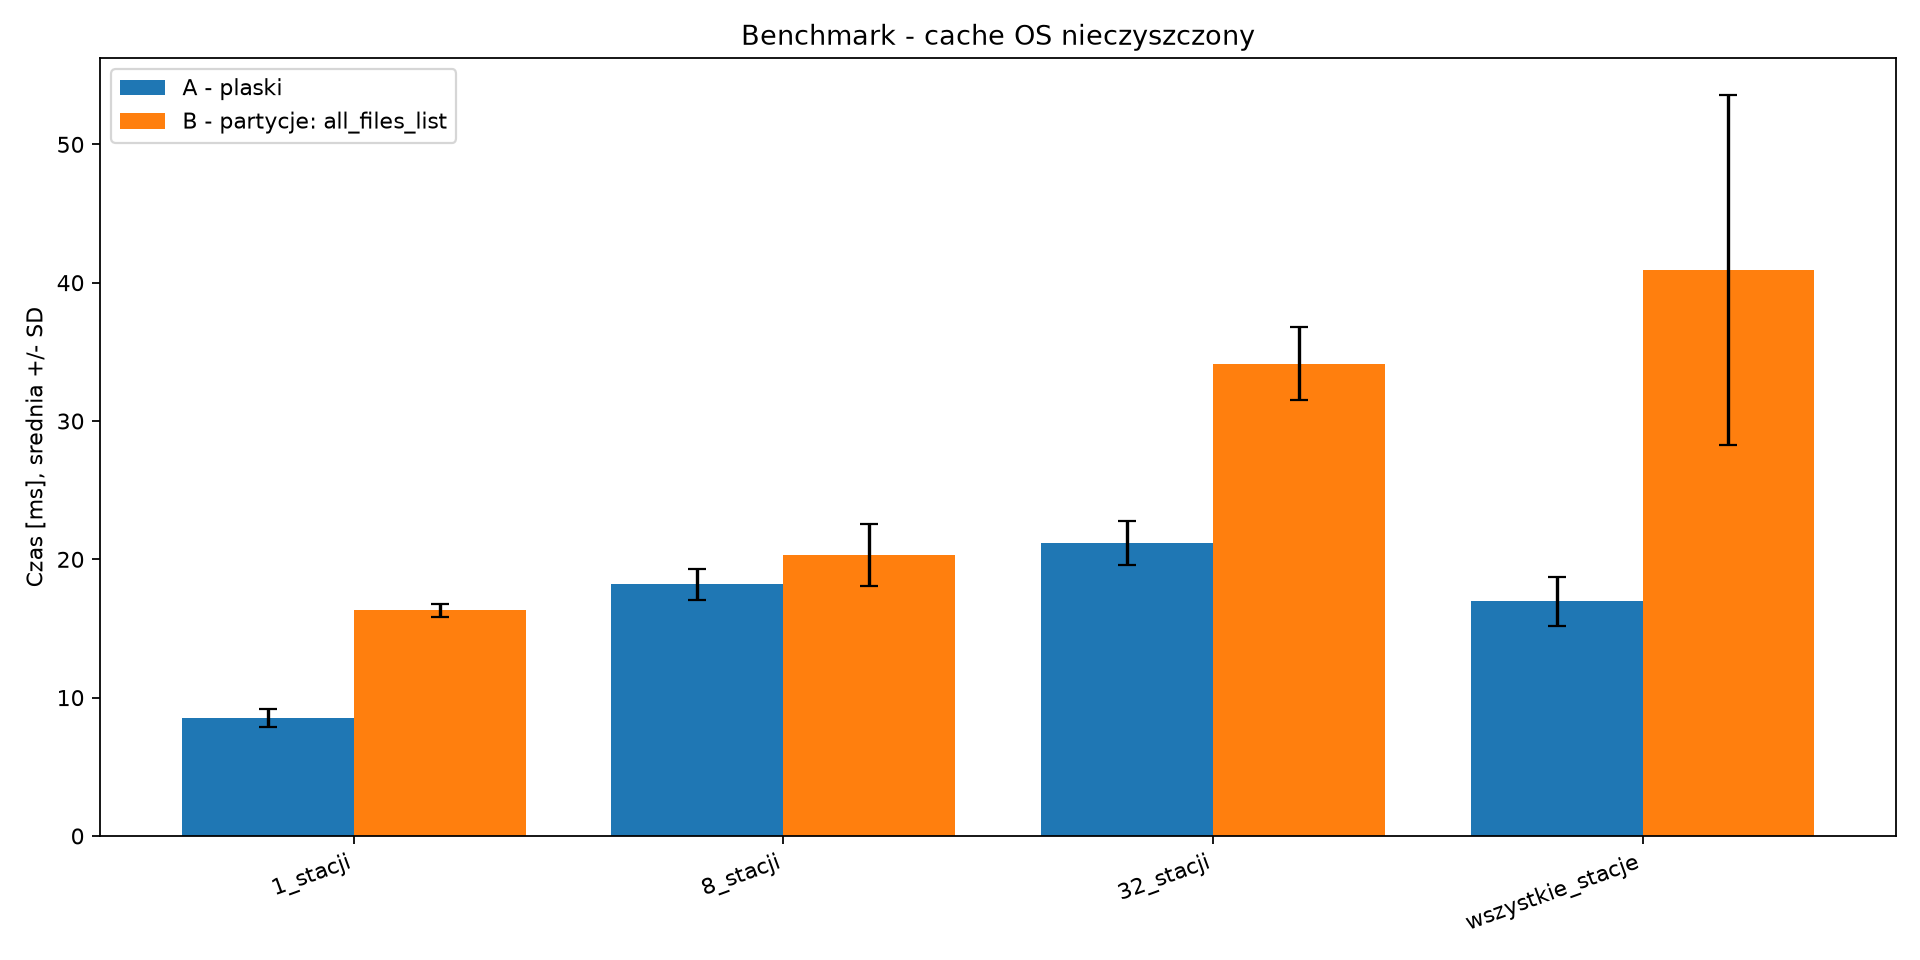

### Zmiana czasu względem A

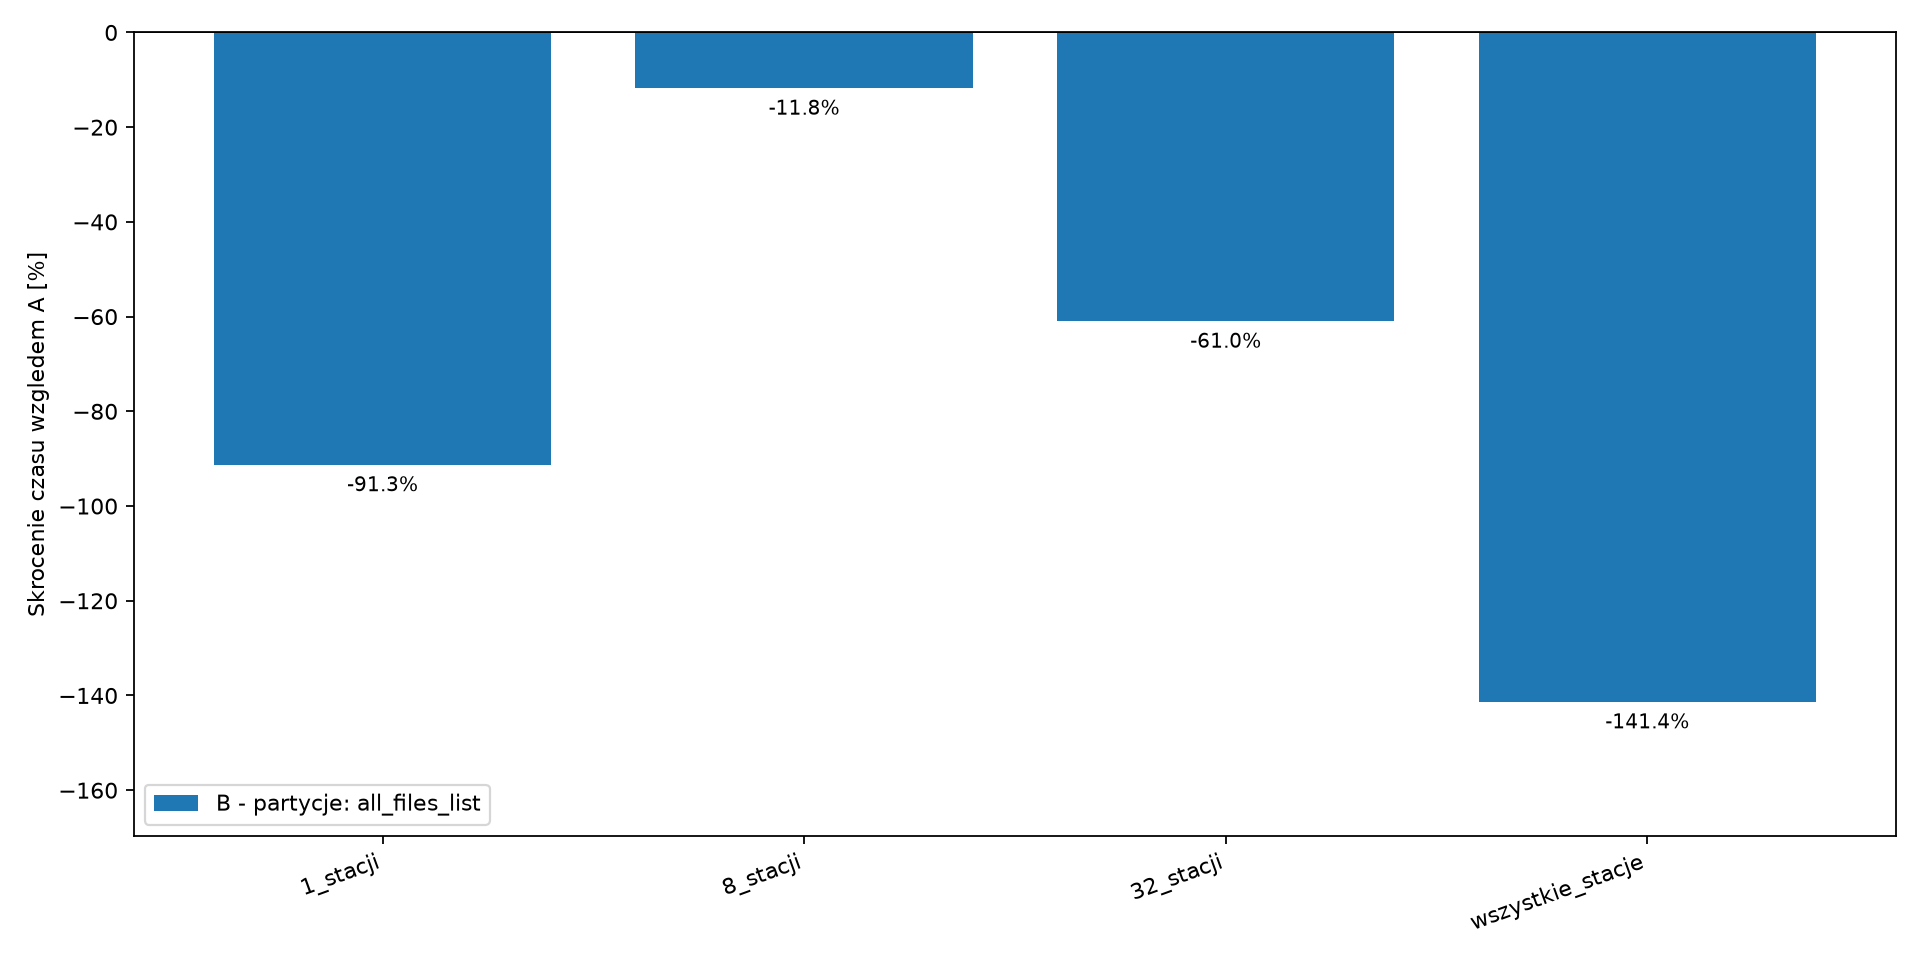

### Wyniki kolejnych powtórzeń

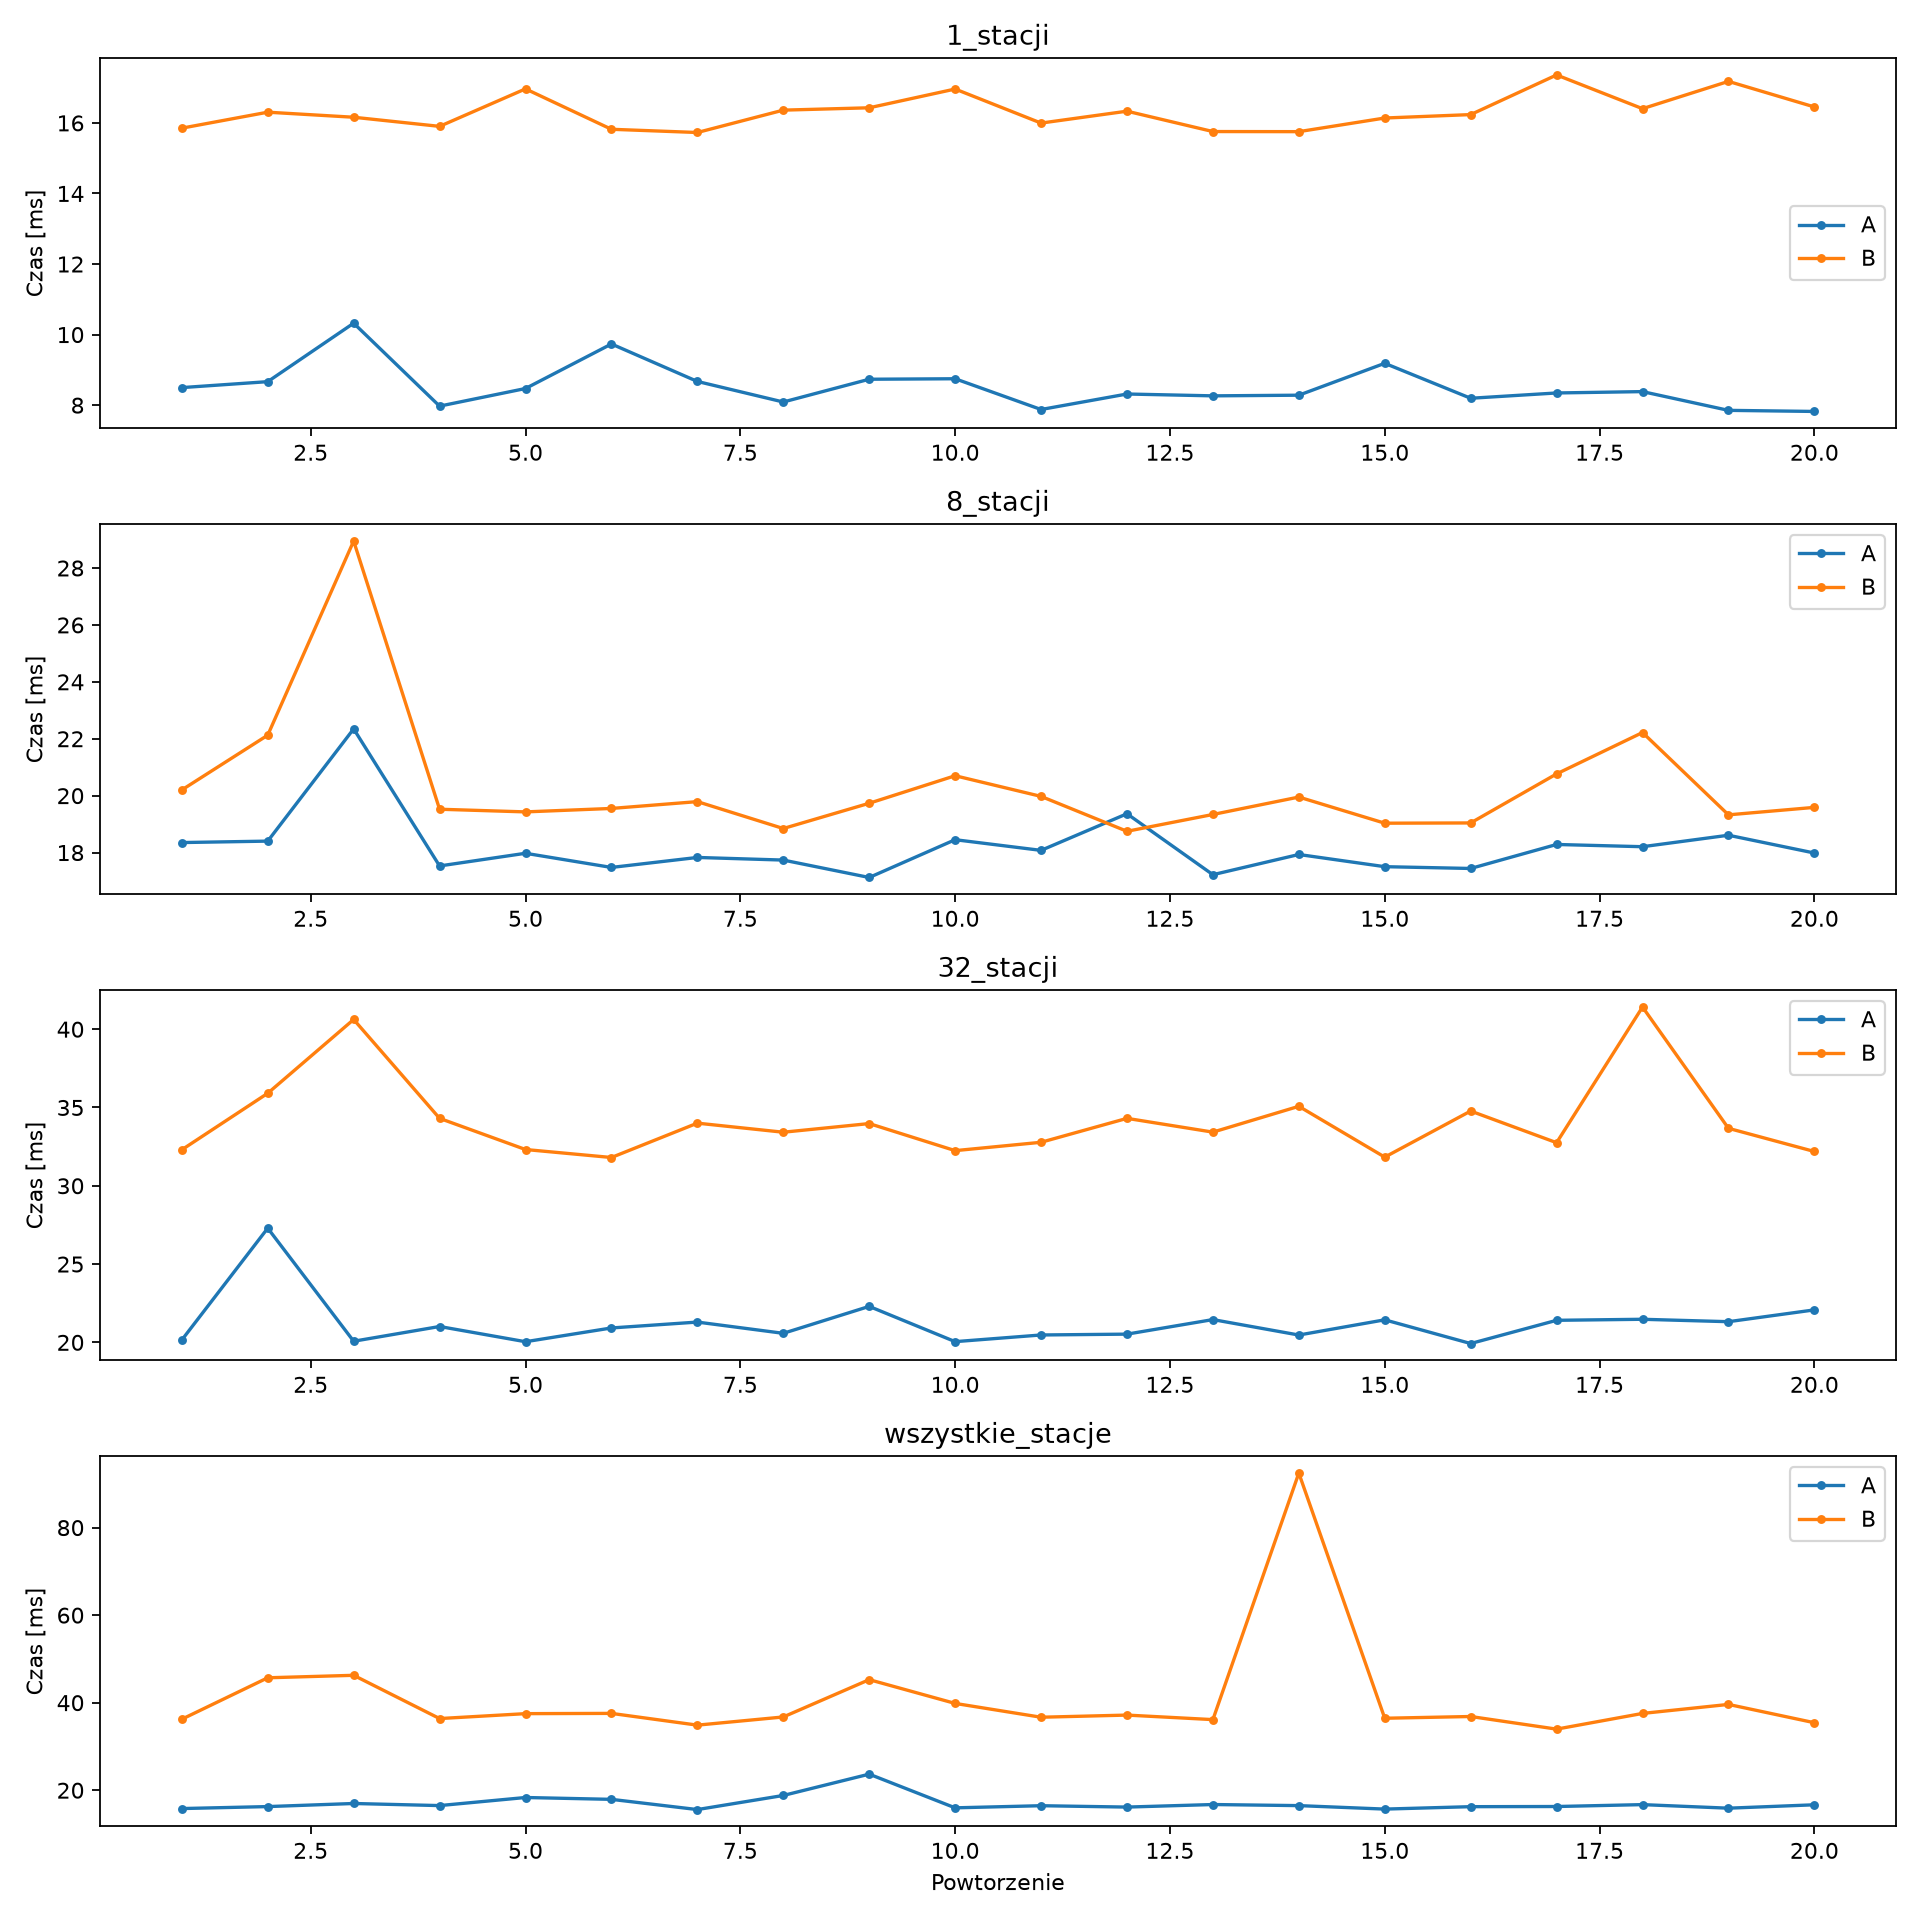

In [12]:
plot_names = [
    ("01_mean_times.png", "Średni czas wykonania"),
    ("02_time_saved.png", "Zmiana czasu względem A"),
    ("03_repetitions.png", "Wyniki kolejnych powtórzeń"),
]
try:
    import matplotlib.pyplot as plt
except ModuleNotFoundError as exc:
    if exc.name != "matplotlib":
        raise
    print("Brak matplotlib. Zainstaluj je w środowisku kernela, aby utworzyć wykresy.")
else:
    figures = []
    try:
        # Zapobiega podwójnemu wyświetleniu przez backend notebooka.
        with plt.ioff():
            figures = benchmark["make_plots"](ctx, timings, summary)
    finally:
        for figure in figures:
            plt.close(figure)

# Wyświetlanie zapisanych plików działa również bez matplotlib.
for filename, title in plot_names:
    path = ctx["report"] / filename
    if path.is_file():
        display(Markdown(f"### {title}"))
        display(Image(filename=str(path), width=1100))
    else:
        print("Nie utworzono wykresu:", filename)

## 8. Dane dla M3

Publikację można wyłączyć przez `PUBLISH_DATASET=False`.
Podczas podmiany katalogu nie należy go równolegle odczytywać.

In [13]:
try:
    if PUBLISH_DATASET:
        published = benchmark["publish_dataset"](ctx)
        print("Dane dla M3:", published)
    else:
        print("Publikacja pominięta. Dane:", ctx["partitioned"])
finally:
    ctx["con"].close()
    print("Połączenie zamknięte")

Dane dla M3: D:\Projekty\gios-bigdata\data\silver\pm25_pogoda_2024_partycje
Połączenie zamknięte


## 9. Interpretacja wyników

Opis powstaje z aktualnych pomiarów: poprawa, niewielka różnica lub pogorszenie.
Przy wyniku ujemnym wskazujemy możliwy wpływ małego zbioru i narzutu wielu plików.
Nie traktujemy tego jako udowodnionej przyczyny. Opis zapisujemy również do raportu.

In [14]:
def describe_results(summary, timings, storage, ctx, small_percent=5.0):
    """Opis pomiarów. Przyczyny są hipotezami, nie wynikiem profilowania I/O."""
    if not math.isfinite(small_percent) or small_percent < 0:
        raise ValueError("Próg niewielkiej różnicy musi być nieujemny i skończony")
    rows = summary.to_dicts()
    raw = timings.to_dicts()
    if not rows:
        raise ValueError("Brak wyników do interpretacji")
    sizes = {r["variant"]: r for r in storage["storage"].to_dicts()}
    a_size, b_size = sizes["A"], sizes["B"]
    variants = ctx.get("variants", ["A", "B"])
    sections = [
        "# Interpretacja wyników",
        (f"Zbiór obejmuje {a_size['rows']:,} wierszy. "
         f"Wariant A zajmuje {a_size['bytes'] / 1_000_000:.2f} MB w jednym pliku, "
         f"a wariant B {b_size['bytes'] / 1_000_000:.2f} MB w {b_size['files']} plikach."),
        (f"Każdą konfigurację zmierzono {ctx['repeats']} razy. "
         "Mierzony czas obejmuje wykonanie zapytania i pobranie wyniku. "
         "Cache systemowy nie był czyszczony."),
        (f"Za niewielką różnicę przyjmujemy zmianę nie większą niż {small_percent:g}% "
         "lub różnicę średnich nieprzekraczającą odchylenia standardowego sparowanych różnic czasów. "
         "To reguła opisowa, a nie test istotności statystycznej."),
    ]
    counts = {v: {"improvement": 0, "small": 0, "loss": 0} for v in variants if v != "A"}
    for row in rows:
        n_selected = next((s.get("selected_stations") for s in ctx["scenarios"] if s["id"] == row["id"]), None)
        title = "Wszystkie stacje — bez filtra" if row["id"] == "control" else f"Liczba stacji: {n_selected}"
        sections.append(f"## {title}")
        for variant in variants:
            if variant == "A":
                continue
            a = float(row["A_mean_ms"])
            b = float(row[f"{variant}_mean_ms"])
            if not (math.isfinite(a) and math.isfinite(b) and a > 0 and b > 0):
                raise ValueError("Nieprawidłowe średnie czasy")
            gain = 100 * (a - b) / a
            baseline = {r["iteration"]: r["time_ms"] for r in raw
                        if r["id"] == row["id"] and r["variant"] == "A"}
            alternate = {r["iteration"]: r["time_ms"] for r in raw
                         if r["id"] == row["id"] and r["variant"] == variant}
            if set(baseline) != set(alternate) or len(baseline) < 2:
                raise ValueError("Brak kompletnych par pomiarowych do interpretacji")
            differences = [baseline[i] - alternate[i] for i in sorted(baseline)]
            paired_sd = statistics.stdev(differences)
            small = abs(gain) <= small_percent or abs(a - b) <= paired_sd
            group = "small" if small else ("improvement" if gain > 0 else "loss")
            counts[variant][group] += 1
            sections.append(
                f"### Wariant {variant} względem A\n\n"
                f"Średni czas: A = {a:.3f} ms; {variant} = {b:.3f} ms. "
                f"Zmiana czasu względem A: {gain:+.2f}%. "
                f"SD sparowanych różnic: {paired_sd:.3f} ms."
            )
            if small:
                text = (
                    "Niewielka lub niestabilna różnica wydajności. "
                    "Zmiana jest mała względem przyjętego progu albo porównywalna z rozrzutem różnic czasów. "
                    "Ta seria nie daje podstaw do uznania jednego układu za wyraźnie korzystniejszy. "
                    "Warto powtórzyć pomiar przy stałym obciążeniu komputera oraz sprawdzić większy zbiór."
                )
            elif gain < 0:
                if row["id"] == "control":
                    text = (
                        "Partycjonowanie zwiększyło czas zapytania obejmującego wszystkie stacje. "
                        "W tym scenariuszu nie ma korzyści z pominięcia stacji na podstawie filtra, "
                        "natomiast pozostaje obsługa wielu plików. "
                        "Dla obecnego zakresu danych narzut tego układu prawdopodobnie przewyższa korzyści; "
                        "pojedynczy plik jest szybszy w zmierzonym scenariuszu."
                    )
                else:
                    text = (
                        "Partycjonowanie zwiększyło czas zapytania. "
                        "Obecny zbiór może być zbyt mały, aby ograniczenie odczytu zrekompensowało "
                        "narzut obsługi wielu niewielkich plików. "
                        "Możliwe przyczyny obejmują planowanie, odczyt metadanych i otwieranie plików; "
                        "przy rozgrzanym cache oszczędność transferu może mieć mniejsze znaczenie. "
                        "Mały rozmiar danych jest prawdopodobnym wyjaśnieniem, nie udowodnioną przyczyną. "
                        "Skuteczność pruning należy osobno potwierdzić w planie zapytania."
                    )
            else:
                if row["id"] == "control":
                    text = (
                        "Wariant partycjonowany skrócił czas pełnej agregacji. "
                        "Nie należy przypisywać tej poprawy pruning po stacji, ponieważ zapytanie nie ma takiego filtra. "
                        "Możliwe znaczenie ma fizyczny układ grup wierszy i równoległość odczytu. "
                        "Przyczynę należy sprawdzić w planie i profilowaniu."
                    )
                else:
                    text = (
                        "Partycjonowanie skróciło czas zapytania. "
                        "Wynik jest zgodny z oczekiwaną korzyścią z ograniczenia zakresu odczytywanych danych, "
                        "o ile plan potwierdza pomijanie niepasujących plików. "
                        "Dla tego scenariusza korzyść czasowa przewyższa narzut obsługi partycji. "
                        "Wyniku nie należy automatycznie przenosić na zapytania obejmujące cały zbiór."
                    )
            if variant == "C":
                text += (
                    " Wariant C korzysta z tych samych plików co B, lecz innego sposobu ich wskazania. "
                    "Jego porównanie z A nie izoluje kosztu globowania; ten aspekt ocenia się, zestawiając B z C."
                )
            sections.append(text)
    sections.append("## Podsumowanie")
    for variant, result in counts.items():
        sections.append(
            f"Wariant {variant}: poprawa w {result['improvement']} scenariuszach, "
            f"niewielka lub niestabilna różnica w {result['small']}, "
            f"pogorszenie w {result['loss']}."
        )
    change = 100 * (b_size["bytes"] - a_size["bytes"]) / a_size["bytes"]
    sections.append(
        f"Zmiana rozmiaru zapisu B względem A wynosi {change:+.2f}%. "
        "Czas wykonania i miejsce na dysku to odrębne kryteria. "
        "Na podstawie tego testu nie wyliczamy kosztów pieniężnych ani faktycznie odczytanych bajtów z dysku."
    )
    sections.append(
        "Przyczyny różnic wymagają osobnego profilowania. "
        "Wielkość zbioru, liczba plików i cache pomagają wyjaśnić wynik, "
        "ale sama różnica czasu nie rozstrzyga, który czynnik był decydujący."
    )
    return "\n\n".join(sections)


interpretation = describe_results(summary, timings, storage, ctx, SMALL_DIFFERENCE_PERCENT)
display(Markdown(interpretation))
interpretation_path = ctx["report"] / "interpretation.md"
interpretation_path.write_text(interpretation, encoding="utf-8")
print("Zapisano opis wyników:", interpretation_path)

# Interpretacja wyników

Zbiór obejmuje 658,800 wierszy. Wariant A zajmuje 24.32 MB w jednym pliku, a wariant B 37.69 MB w 75 plikach.

Każdą konfigurację zmierzono 20 razy. Mierzony czas obejmuje wykonanie zapytania i pobranie wyniku. Cache systemowy nie był czyszczony.

Za niewielką różnicę przyjmujemy zmianę nie większą niż 5% lub różnicę średnich nieprzekraczającą odchylenia standardowego sparowanych różnic czasów. To reguła opisowa, a nie test istotności statystycznej.

## Liczba stacji: 1

### Wariant B względem A

Średni czas: A = 8.522 ms; B = 16.304 ms. Zmiana czasu względem A: -91.32%. SD sparowanych różnic: 0.862 ms.

Partycjonowanie zwiększyło czas zapytania. Obecny zbiór może być zbyt mały, aby ograniczenie odczytu zrekompensowało narzut obsługi wielu niewielkich plików. Możliwe przyczyny obejmują planowanie, odczyt metadanych i otwieranie plików; przy rozgrzanym cache oszczędność transferu może mieć mniejsze znaczenie. Mały rozmiar danych jest prawdopodobnym wyjaśnieniem, nie udowodnioną przyczyną. Skuteczność pruning należy osobno potwierdzić w planie zapytania.

## Liczba stacji: 8

### Wariant B względem A

Średni czas: A = 18.193 ms; B = 20.342 ms. Zmiana czasu względem A: -11.81%. SD sparowanych różnic: 1.425 ms.

Partycjonowanie zwiększyło czas zapytania. Obecny zbiór może być zbyt mały, aby ograniczenie odczytu zrekompensowało narzut obsługi wielu niewielkich plików. Możliwe przyczyny obejmują planowanie, odczyt metadanych i otwieranie plików; przy rozgrzanym cache oszczędność transferu może mieć mniejsze znaczenie. Mały rozmiar danych jest prawdopodobnym wyjaśnieniem, nie udowodnioną przyczyną. Skuteczność pruning należy osobno potwierdzić w planie zapytania.

## Liczba stacji: 32

### Wariant B względem A

Średni czas: A = 21.213 ms; B = 34.156 ms. Zmiana czasu względem A: -61.01%. SD sparowanych różnic: 2.894 ms.

Partycjonowanie zwiększyło czas zapytania. Obecny zbiór może być zbyt mały, aby ograniczenie odczytu zrekompensowało narzut obsługi wielu niewielkich plików. Możliwe przyczyny obejmują planowanie, odczyt metadanych i otwieranie plików; przy rozgrzanym cache oszczędność transferu może mieć mniejsze znaczenie. Mały rozmiar danych jest prawdopodobnym wyjaśnieniem, nie udowodnioną przyczyną. Skuteczność pruning należy osobno potwierdzić w planie zapytania.

## Wszystkie stacje — bez filtra

### Wariant B względem A

Średni czas: A = 16.955 ms; B = 40.927 ms. Zmiana czasu względem A: -141.38%. SD sparowanych różnic: 12.649 ms.

Partycjonowanie zwiększyło czas zapytania obejmującego wszystkie stacje. W tym scenariuszu nie ma korzyści z pominięcia stacji na podstawie filtra, natomiast pozostaje obsługa wielu plików. Dla obecnego zakresu danych narzut tego układu prawdopodobnie przewyższa korzyści; pojedynczy plik jest szybszy w zmierzonym scenariuszu.

## Podsumowanie

Wariant B: poprawa w 0 scenariuszach, niewielka lub niestabilna różnica w 0, pogorszenie w 4.

Zmiana rozmiaru zapisu B względem A wynosi +54.95%. Czas wykonania i miejsce na dysku to odrębne kryteria. Na podstawie tego testu nie wyliczamy kosztów pieniężnych ani faktycznie odczytanych bajtów z dysku.

Przyczyny różnic wymagają osobnego profilowania. Wielkość zbioru, liczba plików i cache pomagają wyjaśnić wynik, ale sama różnica czasu nie rozstrzyga, który czynnik był decydujący.

Zapisano opis wyników: D:\Projekty\gios-bigdata\reports\partition_benchmark\20261121T080738_330090Z_2a55773e\interpretation.md
